# Fault classification from audio and electrical signals

This notebook classifies each recording into one of four classes (`Tilt`, `iO`, `offset`, `oil`) from pre-extracted audio and voltage/current features.

1. Data loading and preprocessing
2. Baseline models trained separately on audio features and on electrical features
3. MLP classifier with sequential feature selection on all features
4. Final model comparison

## Imports

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SequentialFeatureSelector

from sklearn.svm import SVC
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report)

## 1. Data loading and preprocessing

In [ ]:
data = pd.read_csv("All_features_New.csv", index_col="Filename", header=0)

# Recordings without a fault description belong to the "iO" class, so the
# missing descriptions are filled from the "Label" column, which is then dropped.
data["Error_Description"] = data["Error_Description"].fillna(data["Label"])
data = data.drop(columns=["Label"])
print(data.head(3))

         Error_Description     Audio_rms  Audio_zcr  Audio_ptp_amplitude  \
Filename                                                                   
169.csv                 iO  10458.980723   0.043860                47281   
170.csv                 iO  10111.909844   0.046411                47109   
171.csv                 iO  10950.168681   0.042390                48999   

          Audio_skewness  Audio_kurtosis     Audio_std  \
Filename                                                 
169.csv         0.100325       -0.246479  10458.603887   
170.csv         0.068261       -0.168339  10111.903392   
171.csv         0.055829       -0.436742  10949.793021   

          Audio_Spectral_Centroid  Audio_spectral_spread  \
Filename                                                   
169.csv               3348.326751            4365.652557   
170.csv               3182.337388            4177.019293   
171.csv               3196.545468            4178.244850   

          Audio_spectral_en

## 2. Baseline models: audio features vs electrical features

Each family of classical models is tuned with a grid search (5-fold stratified CV), once on the audio features only and once on the voltage/current features only.

### 2.1 Feature sets and train/test split

In [ ]:
# Split the columns into the two sensor groups, keeping the target in both
common = ["Error_Description"]
audio_cols = [c for c in data.columns if c.startswith('Audio')]
other_cols = [c for c in data.columns if c not in audio_cols]

df_audio = data.loc[:, list(dict.fromkeys(common + audio_cols))]
df_voltage = data.loc[:, list(dict.fromkeys(common + other_cols))]


def split_data(data):
    y = data["Error_Description"]
    X = data.drop(columns=['Error_Description'])
    return X, y


X_audio, y_audio = split_data(df_audio)
X_voltage, y_voltage = split_data(df_voltage)

# Same 80/20 split (same seed) for both feature sets
X_audio_train, X_audio_test, y_audio_train, y_audio_test = train_test_split(X_audio, y_audio, train_size=0.8, random_state=42, shuffle=True)
X_voltage_train, X_voltage_test, y_voltage_train, y_voltage_test = train_test_split(X_voltage, y_voltage, train_size=0.8, random_state=42, shuffle=True)

### 2.2 Pipelines and hyperparameter grids

In [ ]:
# One pipeline per model and per feature set
pipe_audio_svc = Pipeline([('clf', SVC())])
pipe_audio_gb = Pipeline([('clf', GradientBoostingClassifier(random_state=42))])
pipe_audio_rf = Pipeline([('clf', RandomForestClassifier(random_state=42))])
pipe_audio_lr = Pipeline([('clf', LogisticRegression(max_iter=1000))])
pipe_audio_knn = Pipeline([('clf', KNeighborsClassifier())])

pipe_voltage_svc = Pipeline([('clf', SVC())])
pipe_voltage_gb = Pipeline([('clf', GradientBoostingClassifier(random_state=42))])
pipe_voltage_rf = Pipeline([('clf', RandomForestClassifier(random_state=42))])
pipe_voltage_lr = Pipeline([('clf', LogisticRegression(max_iter=1000))])
pipe_voltage_knn = Pipeline([('clf', KNeighborsClassifier())])

In [ ]:
param_grid_SVC = {
    'clf__C': [0.01, 0.1, 1, 10]
}
param_grid_gb = {
    'clf__n_estimators': [100, 200],
    'clf__learning_rate': [0.05, 0.1],
    'clf__max_depth': [3, 5]
}
param_grid_lr = {
    'clf__C': [0.01, 0.1, 1, 10],
    'clf__solver': ['lbfgs', 'liblinear', 'newton']
}
param_grid_rf = {
    'clf__n_estimators': [100, 200],
    'clf__max_depth': [None, 10, 20]
}
param_grid_knn = {
    'clf__n_neighbors': [3, 5, 7, 9]
}

models_audio = {
    'Logistic Regression Audio': (pipe_audio_lr, param_grid_lr),
    'KNN Audio': (pipe_audio_knn, param_grid_knn),
    'Random Forest Audio': (pipe_audio_rf, param_grid_rf),
    'Gradient Boosting Audio': (pipe_audio_gb, param_grid_gb),
    'SVC Audio': (pipe_audio_svc, param_grid_SVC),
}

models_voltage = {
    'Logistic Regression Voltage': (pipe_voltage_lr, param_grid_lr),
    'KNN Voltage': (pipe_voltage_knn, param_grid_knn),
    'Random Forest Voltage': (pipe_voltage_rf, param_grid_rf),
    'Gradient Boosting Voltage': (pipe_voltage_gb, param_grid_gb),
    'SVC Voltage': (pipe_voltage_svc, param_grid_SVC),
}

### 2.3 Grid search

In [ ]:
# Audio features
results_audio = {}

for name, (pipe, params) in models_audio.items():
    gs_audio = GridSearchCV(pipe, params, cv=StratifiedKFold(5), scoring="accuracy", n_jobs=1)
    gs_audio.fit(X_audio_train, y_audio_train)
    results_audio[name] = gs_audio
    print(f"{name} best audio score: {gs_audio.best_score_:.4f}")
    print(f"{name} best audio params: {gs_audio.best_params_}\n")

Logistic Regression Audio best audio score: 0.7562
Logistic Regression Audio best audio params: {'clf__C': 0.01, 'clf__solver': 'lbfgs'}

KNN Audio best audio score: 0.5938
KNN Audio best audio params: {'clf__n_neighbors': 3}

Random Forest Audio best audio score: 0.9437
Random Forest Audio best audio params: {'clf__max_depth': None, 'clf__n_estimators': 100}

Gradient Boosting Audio best audio score: 0.9187
Gradient Boosting Audio best audio params: {'clf__learning_rate': 0.1, 'clf__max_depth': 5, 'clf__n_estimators': 200}

SVC Audio best audio score: 0.5563
SVC Audio best audio params: {'clf__C': 10}



In [ ]:
# Voltage/current features
results_voltage = {}

for name, (pipe, params) in models_voltage.items():
    gs = GridSearchCV(pipe, params, cv=StratifiedKFold(5), scoring="accuracy", n_jobs=1)
    gs.fit(X_voltage_train, y_voltage_train)
    results_voltage[name] = gs
    print(f"{name} best voltage score: {gs.best_score_:.4f}")
    print(f"{name} best voltage params: {gs.best_params_}\n")

Logistic Regression Voltage best voltage score: 0.8063
Logistic Regression Voltage best voltage params: {'clf__C': 1, 'clf__solver': 'lbfgs'}

KNN Voltage best voltage score: 0.7125
KNN Voltage best voltage params: {'clf__n_neighbors': 3}

Random Forest Voltage best voltage score: 0.8750
Random Forest Voltage best voltage params: {'clf__max_depth': None, 'clf__n_estimators': 100}

Gradient Boosting Voltage best voltage score: 0.8750
Gradient Boosting Voltage best voltage params: {'clf__learning_rate': 0.05, 'clf__max_depth': 3, 'clf__n_estimators': 100}

SVC Voltage best voltage score: 0.6500
SVC Voltage best voltage params: {'clf__C': 10}



### 2.4 Evaluation on the test set

In [ ]:
# Display order of the models in the bar charts
model_order_audio = [
    "Random Forest Audio",
    "Logistic Regression Audio",
    "SVC Audio",
    "Gradient Boosting Audio",
    "KNN Audio"
]

model_order_voltage = [
    "Random Forest Voltage",
    "Logistic Regression Voltage",
    "SVC Voltage",
    "Gradient Boosting Voltage",
    "KNN Voltage"
]

metrics = ["Accuracy", "F1-score", "Precision", "Recall"]
width = 0.2

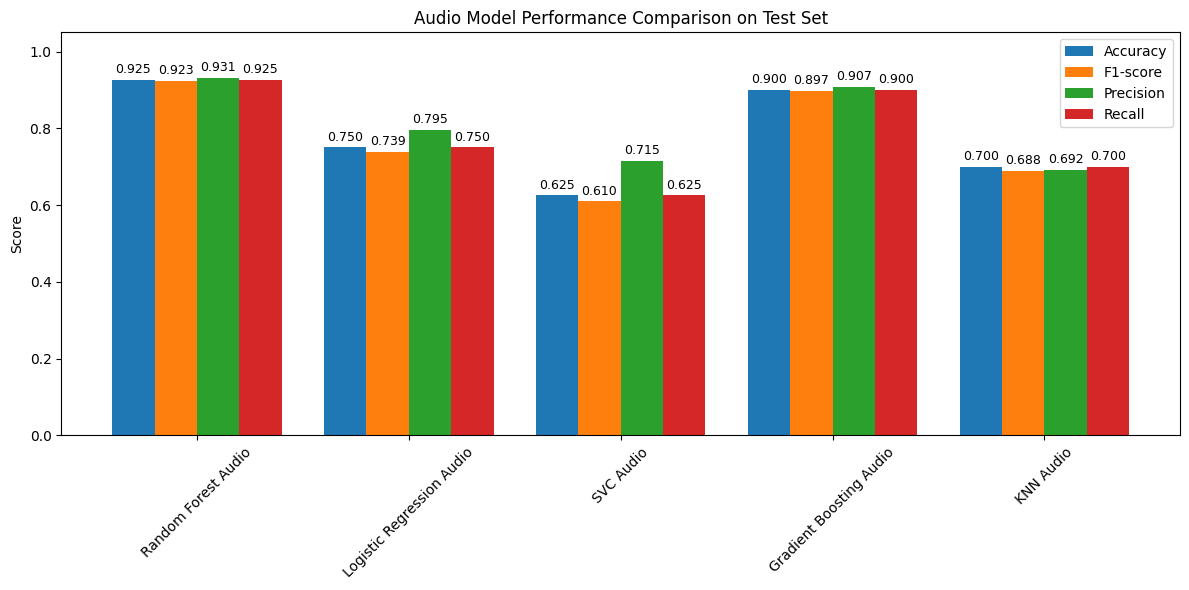

In [ ]:
# Test-set metrics of the best audio models (weighted averages over the 4 classes)
metrics_audio = {"Model": [], "Accuracy": [], "Precision": [], "Recall": [], "F1-score": []}

for name, gs in results_audio.items():
    best_model = gs.best_estimator_
    y_pred = best_model.predict(X_audio_test)

    metrics_audio["Model"].append(name)
    metrics_audio["Accuracy"].append(accuracy_score(y_audio_test, y_pred))
    metrics_audio["Precision"].append(precision_score(y_audio_test, y_pred, average="weighted"))
    metrics_audio["Recall"].append(recall_score(y_audio_test, y_pred, average="weighted"))
    metrics_audio["F1-score"].append(f1_score(y_audio_test, y_pred, average="weighted"))

metrics_audio_df = pd.DataFrame(metrics_audio)

metrics_audio_df_ordered = (
    metrics_audio_df
    .set_index("Model")
    .loc[model_order_audio]
    .reset_index()
)

models = metrics_audio_df_ordered["Model"]
x = np.arange(len(models))

plt.figure(figsize=(12, 6))

for i, metric in enumerate(metrics):
    bars = plt.bar(
        x + i * width,
        metrics_audio_df_ordered[metric],
        width,
        label=metric
    )
    # Write the score above each bar
    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.01,
            f"{height:.3f}",
            ha="center",
            va="bottom",
            fontsize=9
        )

plt.xticks(x + width * 1.5, models, rotation=45)
plt.ylabel("Score")
plt.title("Audio Model Performance Comparison on Test Set")
plt.ylim(0, 1.05)
plt.legend()
plt.tight_layout()
plt.show()

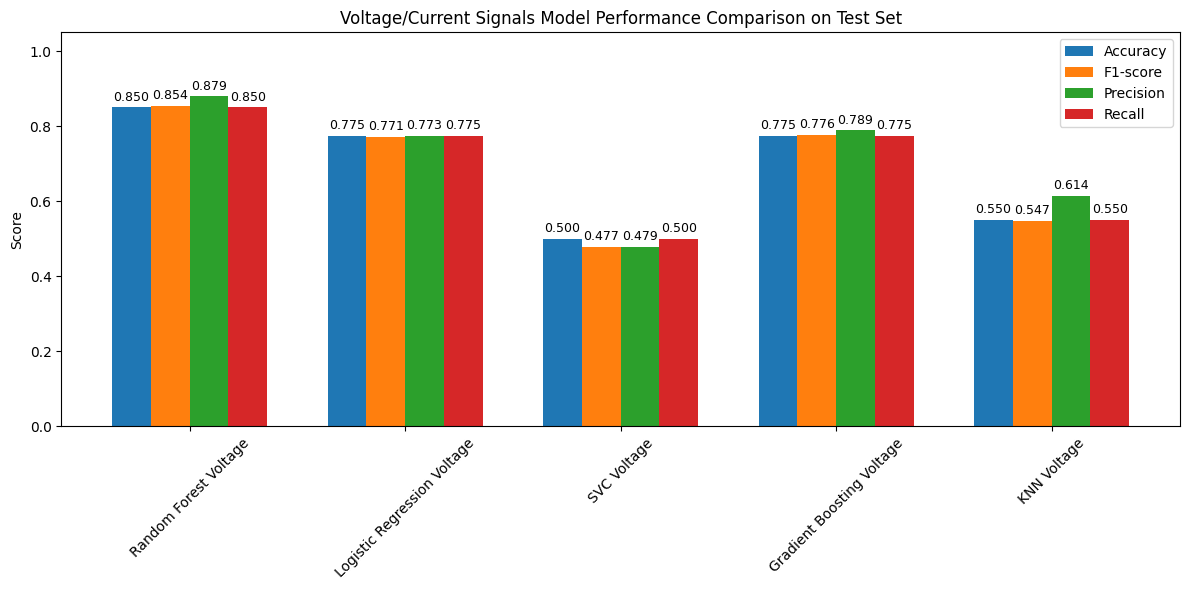

In [ ]:
# Same evaluation for the voltage/current models
metrics_voltage = {"Model": [], "Accuracy": [], "Precision": [], "Recall": [], "F1-score": []}

for name, gs in results_voltage.items():
    best_model = gs.best_estimator_
    y_pred = best_model.predict(X_voltage_test)

    metrics_voltage["Model"].append(name)
    metrics_voltage["Accuracy"].append(accuracy_score(y_voltage_test, y_pred))
    metrics_voltage["Precision"].append(precision_score(y_voltage_test, y_pred, average="weighted"))
    metrics_voltage["Recall"].append(recall_score(y_voltage_test, y_pred, average="weighted"))
    metrics_voltage["F1-score"].append(f1_score(y_voltage_test, y_pred, average="weighted"))

metrics_voltage_df = pd.DataFrame(metrics_voltage)

metrics_voltage_df_ordered = (
    metrics_voltage_df
    .set_index("Model")
    .loc[model_order_voltage]
    .reset_index()
)

models = metrics_voltage_df_ordered["Model"]
x = np.arange(len(models))

plt.figure(figsize=(12, 6))

for i, metric in enumerate(metrics):
    bars = plt.bar(
        x + i * width,
        metrics_voltage_df_ordered[metric],
        width,
        label=metric
    )
    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.01,
            f"{height:.3f}",
            ha="center",
            va="bottom",
            fontsize=9
        )

plt.xticks(x + width * 1.5, models, rotation=45)
plt.ylabel("Score")
plt.title("Voltage/Current Signals Model Performance Comparison on Test Set")
plt.ylim(0, 1.05)
plt.legend()
plt.tight_layout()
plt.show()

## 3. MLP with sequential feature selection

The MLP uses all features (audio + electrical). A forward sequential feature selector first picks a subset of features, then the MLP hyperparameters are tuned by grid search.

### 3.1 Label encoding and train/test split

In [ ]:
df = data.copy()

# Keep the text labels for the final export, and encode the target as integers
df["Error_Description_original"] = df["Error_Description"]
le = LabelEncoder()
df["Error_Description"] = le.fit_transform(df["Error_Description"])
print(le.classes_)

y = df["Error_Description"]
df.to_csv("df_post_traitement.csv", index=True)

# Features only: drop the text label and the encoded target (first column)
X = df.drop(columns=["Error_Description_original"]).iloc[:, 1:]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### 3.2 Forward sequential feature selection

In [ ]:
# A small MLP is used as the estimator to score candidate feature subsets
model = MLPClassifier(hidden_layer_sizes=(20,), max_iter=200)
sfs = SequentialFeatureSelector(model, n_features_to_select='auto', direction='forward', scoring="accuracy", n_jobs=-1, cv=StratifiedKFold(5))
sfs.fit(X_train, y_train)

selected = X_train.columns[sfs.get_support()]
print(selected)
X_train_selected = X_train[selected]
X_test_selected = X_test[selected]

Index(['Audio_zcr', 'Audio_skewness', 'Audio_kurtosis',
       'Audio_spectral_entropy', 'Audio_spectral_flatness',
       'Audio_freq_peak_0_50_Hz', 'Audio_freq_peak_50_100_Hz',
       'Audio_freq_peak_0_250_Hz', 'Audio_skewness_fft', 'Audio_kurtosis_fft',
       'Voltage_Mean', 'Resistance_Mean', 'Voltage_Std', 'Resistance_Std',
       'Voltage_Ptp', 'Resistance_Ptp', 'Voltage_Max', 'Resistance_Max',
       'Current_Skewness', 'Voltage_Skewness', 'Resistance_Skewness',
       'Power_Skewness', 'Voltage_Kurtosis', 'Resistance_Kurtosis',
       'Power_Kurtosis', 'Current_0_200_Mean', 'Voltage_0_200_Mean',
       'Resistance_0_200_Mean', 'Power_0_200_Mean', 'Voltage_0_200_Std',
       'Resistance_0_200_Std', 'Current_0_200_Skewness',
       'Voltage_0_200_Skewness', 'Resistance_0_200_Skewness',
       'Power_0_200_Skewness', 'Current_0_200_Kurtosis',
       'Voltage_0_200_Kurtosis', 'Resistance_0_200_Kurtosis',
       'Power_0_200_Kurtosis', 'Power_1000_2000_Skewness',
       'Power_100

### 3.3 MLP hyperparameter search

In [ ]:
# Features are standardized inside the pipeline so scaling is fitted on each CV training fold only
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('nn', MLPClassifier(max_iter=5000, verbose=0))
])

param_grid = {
    'nn__hidden_layer_sizes': [(20,), (30,), (40,), (50,), (62,), (40, 20), (20, 20)],
    'nn__alpha': [0.05, 0.5, 0.6, 0.7],
    'nn__learning_rate_init': [0.001, 0.0005, 0.0001],
    'nn__activation': ['relu', 'tanh']
}

grid = GridSearchCV(estimator=pipeline, param_grid=param_grid, cv=StratifiedKFold(5), n_jobs=-1, scoring='accuracy')

In [ ]:
grid.fit(X_train_selected, y_train)
print("Best parameters:", grid.best_params_)
print("Best CV score:", grid.best_score_)

best_nn = grid.best_estimator_.named_steps['nn']
loss_curve = best_nn.loss_curve_

Best parameters: {'nn__activation': 'relu', 'nn__alpha': 0.6, 'nn__hidden_layer_sizes': (20, 20), 'nn__learning_rate_init': 0.0001}
Best CV score: 0.98125


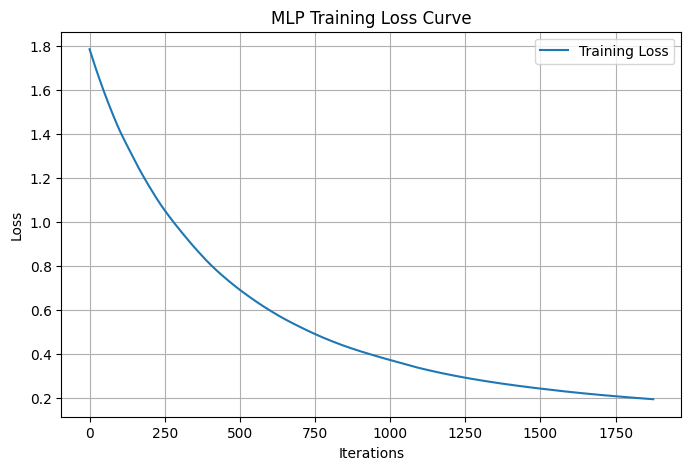

In [ ]:
# Training loss of the best MLP (refitted on the whole training set)
plt.figure(figsize=(8, 5))
plt.plot(loss_curve, label='Training Loss')
plt.xlabel('Iterations')
plt.ylabel('Loss')
plt.title('MLP Training Loss Curve')
plt.grid(True)
plt.legend()
plt.show()

### 3.4 Evaluation on the test set

In [ ]:
y_pred = grid.predict(X_test_selected)
y_pred_proba = grid.predict_proba(X_test_selected)

accuracy  = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='weighted')
recall    = recall_score(y_test, y_pred, average='weighted')
f1        = f1_score(y_test, y_pred, average='weighted')
# One-vs-rest ROC AUC, computed from the predicted class probabilities
roc_curve = roc_auc_score(y_test, y_pred_proba, multi_class="ovr")
print("ROC AUC Score :", roc_curve)
print("\n--- Final Evaluation on Test Set ---")
print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

ROC AUC Score : 0.9804561944879833

--- Final Evaluation on Test Set ---
Accuracy : 0.875
Precision: 0.8941666666666667
Recall   : 0.875
F1 Score : 0.8780193236714975


In [ ]:
# Confusion matrix with the classes shown in a fixed order
desired_labels = ["offset", "oil", "iO", "Tilt"]

# Map each class name to its encoded integer
actual_class_names = le.inverse_transform(np.unique(y))
mapping = dict(zip(actual_class_names, np.unique(y)))
encoded_order = [mapping[label] for label in desired_labels]

# Rows = true labels, columns = predicted labels
cm = confusion_matrix(y_test, y_pred, labels=encoded_order)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=desired_labels,
            yticklabels=desired_labels)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.show()

In [ ]:
# Classes are encoded as 0 = Tilt, 1 = iO, 2 = offset, 3 = oil
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.91      0.87        11
           1       1.00      0.80      0.89        15
           2       0.70      0.88      0.78         8
           3       1.00      1.00      1.00         6

    accuracy                           0.88        40
   macro avg       0.88      0.90      0.88        40
weighted avg       0.89      0.88      0.88        40



In [ ]:
# Export the predicted and true text labels for each test file
y_pred_text = le.inverse_transform(y_pred)
df_test = df.loc[X_test.index].copy()
df_test = pd.DataFrame({
    "Predicted_label": y_pred_text,
    "True_label": df_test["Error_Description_original"]
})
df_test.to_csv("predictions_results.csv", index=True)

print("Fichier CSV généré : predictions_results.csv")

Fichier CSV généré : predictions_results.csv


### 3.5 Robustness over several train/test splits

The full pipeline (split, feature selection, grid search, evaluation) is repeated with a different random split each time, to check that the test score does not depend on one lucky split.

In [ ]:
N_RUNS = 5

accuracies = []
f1_scores = []
conf_matrices = []

for i in range(N_RUNS):
    print(f"=== RUN {i+1}/{N_RUNS} ===")

    # 1) Split with a new seed
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42+i
    )

    # 2) Feature selection on this training set
    sfs = SequentialFeatureSelector(
        model,
        n_features_to_select='auto',
        direction='forward',
        scoring='accuracy',
        n_jobs=-1,
        cv=StratifiedKFold(5)
    )
    sfs.fit(X_train, y_train)

    selected = X_train.columns[sfs.get_support()]
    X_train_sel = X_train[selected]
    X_test_sel  = X_test[selected]

    # 3) Grid search of the MLP pipeline
    grid.fit(X_train_sel, y_train)
    print("Best parameters:", grid.best_params_)

    # 4) Predictions
    y_pred = grid.predict(X_test_sel)
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))

    # 5) Metrics
    acc = accuracy_score(y_test, y_pred)
    f1  = f1_score(y_test, y_pred, average='weighted')
    cm  = confusion_matrix(y_test, y_pred)

    accuracies.append(acc)
    f1_scores.append(f1)
    conf_matrices.append(cm)


# Aggregated results over all runs
mean_acc = np.mean(accuracies)
std_acc  = np.std(accuracies)

mean_f1  = np.mean(f1_scores)
std_f1   = np.std(f1_scores)

mean_cm = np.mean(conf_matrices, axis=0)

print(f"\n==================== FINAL SUMMARY OVER {N_RUNS} RUNS ====================")
print(f"Average Test Accuracy : {mean_acc:.4f} ± {std_acc:.4f}")
print(f"Average F1-score      : {mean_f1:.4f} ± {std_f1:.4f}")
print("\nAverage Confusion Matrix:")
print(pd.DataFrame(mean_cm))

=== RUN 1/5 ===
Best parameters: {'nn__activation': 'relu', 'nn__alpha': 0.5, 'nn__hidden_layer_sizes': (20,), 'nn__learning_rate_init': 0.001}

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.91      0.91        11
           1       1.00      0.80      0.89        15
           2       0.64      0.88      0.74         8
           3       1.00      1.00      1.00         6

    accuracy                           0.88        40
   macro avg       0.89      0.90      0.88        40
weighted avg       0.90      0.88      0.88        40

=== RUN 2/5 ===
Best parameters: {'nn__activation': 'relu', 'nn__alpha': 0.6, 'nn__hidden_layer_sizes': (30,), 'nn__learning_rate_init': 0.0001}

Classification Report:
              precision    recall  f1-score   support

           0       0.92      1.00      0.96        11
           1       1.00      0.94      0.97        16
           2       1.00      1.00      1.00         6
           

## 4. Final comparison

The scores below are entered by hand from previous runs.

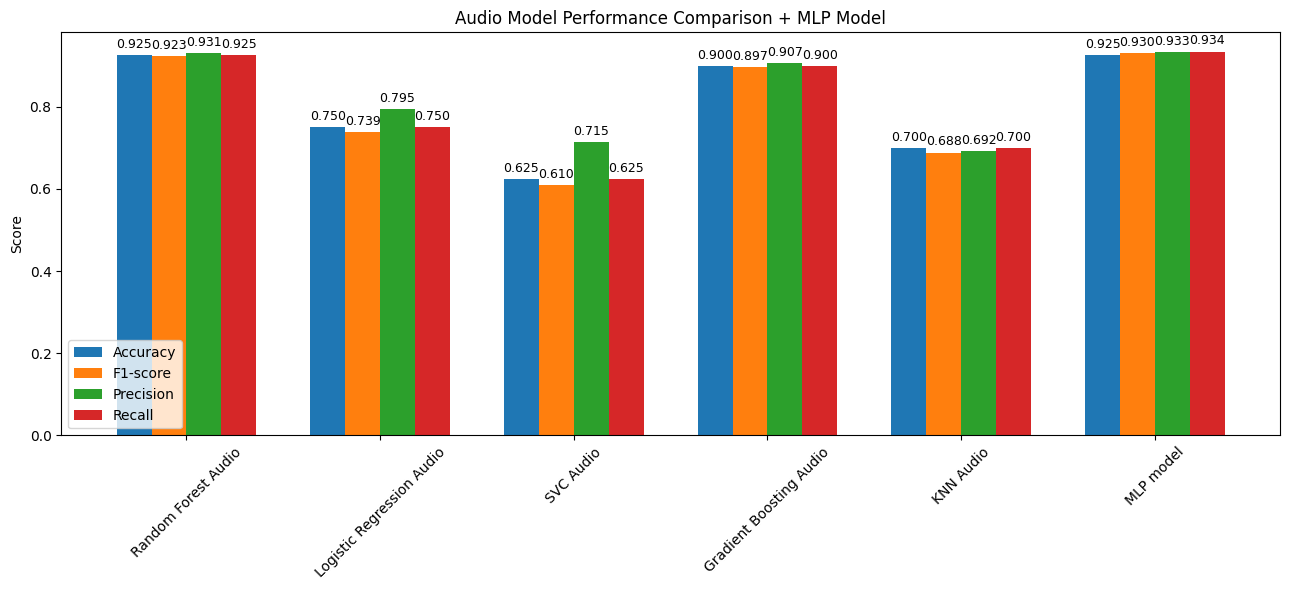

In [ ]:
# Audio baselines + MLP scores averaged over the repeated runs
overall_metrics_audio = {
    "Accuracy": 0.9250,
    "F1-score": 0.9300,
    "Precision": 0.9330,
    "Recall": 0.9345
}

metrics_audio_plot_df = pd.concat(
    [
        metrics_audio_df_ordered.copy(),
        pd.DataFrame([{
            "Model": "MLP model",
            "Accuracy": overall_metrics_audio["Accuracy"],
            "F1-score": overall_metrics_audio["F1-score"],
            "Precision": overall_metrics_audio["Precision"],
            "Recall": overall_metrics_audio["Recall"]
        }])
    ],
    ignore_index=True
)

models = metrics_audio_plot_df["Model"]
x = np.arange(len(models))
width = 0.18

plt.figure(figsize=(13, 6))

for i, metric in enumerate(metrics):
    bars = plt.bar(
        x + i * width,
        metrics_audio_plot_df[metric],
        width,
        label=metric
    )
    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.01,
            f"{height:.3f}",
            ha="center",
            va="bottom",
            fontsize=9
        )

plt.xticks(x + width * 1.5, models, rotation=45)
plt.ylabel("Score")
plt.title("Audio Model Performance Comparison + MLP Model")
plt.legend()
plt.tight_layout()
plt.show()

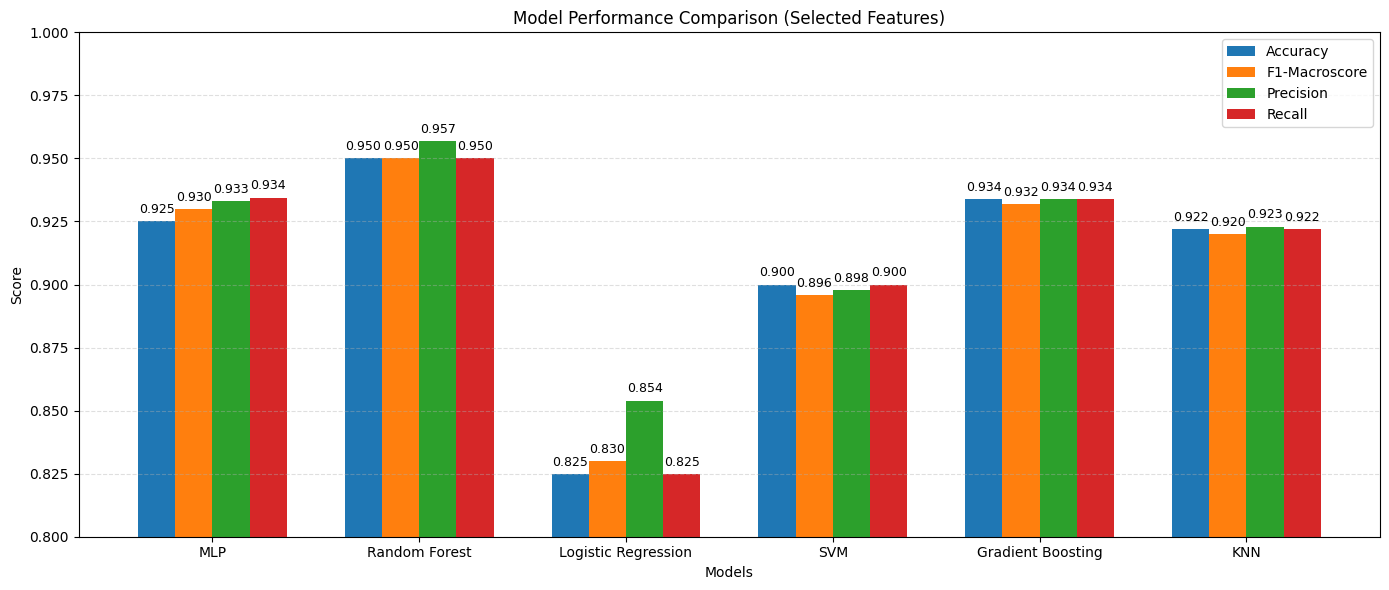

In [ ]:
# All models trained on the selected features
summary_data = {
    "Model": ["MLP", "Random Forest", "Logistic Regression", "SVM", "Gradient Boosting", "KNN"],
    "Accuracy":  [0.9250, 0.950, 0.825, 0.900, 0.934, 0.922],
    "F1-score":  [0.9300, 0.950, 0.830, 0.896, 0.932, 0.920],
    "Precision": [0.9330, 0.957, 0.854, 0.898, 0.934, 0.923],
    "Recall":    [0.9345, 0.950, 0.825, 0.900, 0.934, 0.922]
}
df_summary = pd.DataFrame(summary_data)

x = np.arange(len(df_summary["Model"]))
width = 0.18

plt.figure(figsize=(14, 6))

for i, metric in enumerate(metrics):
    bars = plt.bar(
        x + i * width,
        df_summary[metric],
        width,
        label=metric.replace("-", "-Macro"),
    )
    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.002,
            f"{height:.3f}",
            ha="center",
            va="bottom",
            fontsize=9
        )

plt.xticks(x + width * 1.5, df_summary["Model"])
plt.ylabel("Score")
plt.xlabel("Models")
plt.title("Model Performance Comparison (Selected Features)")
plt.ylim(0.80, 1.00)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()